# Pass-04

## Problem Definition


Business problem: estimate a house’s sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import library
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

#measures prediction error (used for RMSE)
from sklearn.metrics import mean_squared_error

# trains and tests 10 times, averages the scores
from sklearn.model_selection import cross_val_score # trains and tests 10 times, averages the scores

# sm: draws the QQ plot for residual analysis
import statsmodels.api as sm

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load data
house_df= pd.read_csv(url,
               usecols= ['Lot Frontage','SalePrice'])





In [4]:
# look at first and last few rows
print(house_df.head())
print(house_df.tail())

   Lot Frontage  SalePrice
0          62.0     115400
1          72.0      90000
2          50.0     141000
3          68.0     254000
4          60.0     155000
      Lot Frontage  SalePrice
2632          52.0     114500
2633          74.0     162000
2634          61.0     211500
2635          78.0     165000
2636          41.0     225000


In [5]:
# look at shape and size

print(house_df.shape)
print(house_df.size)


(2637, 2)
5274


In [6]:
# display meta data (info)
house_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Lot Frontage  2188 non-null   float64
 1   SalePrice     2637 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 41.3 KB


In [7]:
# display summary statistics
house_df.describe()



,Lot Frontage,SalePrice
count,2188.000000,2637.000000
mean,69.166819,179986.230186
std,23.356779,78309.251522
min,21.000000,12789.000000
25%,58.000000,129500.000000
50%,68.000000,160000.000000
75%,80.000000,213000.000000
max,313.000000,745000.000000


In [8]:
# Columns data types
house_df.dtypes.sort_values()


,0
SalePrice,int64
Lot Frontage,float64


In [9]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [10]:
# look for nulls in target and features
house_df.isnull().sum().sort_values(ascending=False)

,0
Lot Frontage,449
SalePrice,0


In [11]:
# look for nulls in feature in percentage
house_df['Lot Frontage'].isnull().mean() * 100

np.float64(17.02692453545696)

## Data Cleaning


### Backup 1

In [12]:
# make backup
house_df_backup= house_df.copy()

In [13]:
# restore from backup
house_df = house_df_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

### Impute

In [14]:
# Calculate the median
median_frontage = house_df['Lot Frontage'].median()
print(median_frontage)

# Fill nulls with the median
house_df['Lot Frontage']= house_df['Lot Frontage'].fillna(median_frontage)

#verify there are no nulls
house_df.isnull().sum()


68.0


,0
Lot Frontage,0
SalePrice,0


In [15]:
house_df['Lot Frontage'].median()

68.0

## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

In [16]:
# Calculate a correlation matrix for target
house_df.corr() ;

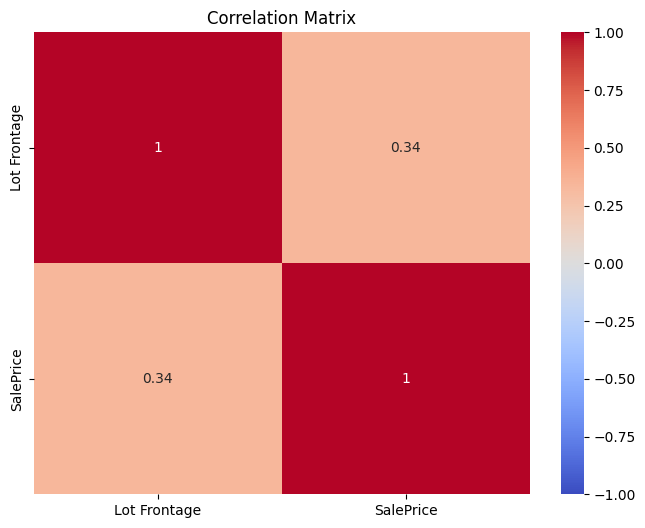

In [17]:
# Display the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(house_df.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()

In [18]:
# there only one feature. Cannot check requirement #2

## Processing



### Fit & Assess Linear Regression

#### Using Sklearn

In [19]:
# break data into training and testing sets
X= house_df [['Lot Frontage']]
y= house_df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=4)


In [20]:
# Fit a linear model using SKlearn
model=LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

[(247000, np.float64(202165.39952759026)),
 (135000, np.float64(243764.91004508053)),
 (165000, np.float64(197123.0346163793)),
 (127500, np.float64(159305.29778229722)),
 (105000, np.float64(175692.9837437328)),
 (100000, np.float64(188298.89602176016)),
 (201800, np.float64(178214.16619933827)),
 (235128, np.float64(208468.35566660392)),
 (155000, np.float64(193341.26093297108)),
 (104000, np.float64(208468.35566660392))]

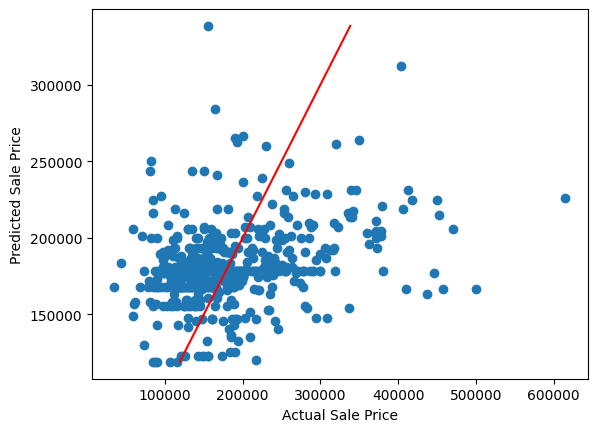

In [21]:
# See how well the model does compare to the test data

plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)], [min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price');

list(zip(y_test, y_pred))[:10]

In [22]:
# RMS on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse} ")

#RMSE- shows the amount the model was wrong

RMSE: 75252.77290876149 


In [23]:
# What if we skip the model and guess the average price for every house?

# The average sale price in the training data
average_price = y_train.mean()
print('Average price: $', round(average_price))

# Use that same guess for every test house
average_guess = [average_price] * len(y_test)

# How much that guess misses by
average_rmse = mean_squared_error(y_test, average_guess) ** 0.5
print('Average-guess RMSE: $', round(average_rmse))

Average price: $ 179040
Average-guess RMSE: $ 79225


In [24]:
# Use cross validation to assess model performance
results = cross_val_score(model, X, y, scoring='neg_root_mean_squared_error', cv=100)
cv_rmse = abs(results.mean())
print(f"CV RMSE: {cv_rmse}")

#Run validation multiple times compare to single cv number barely change
#the single sv lucky that how the model work

CV RMSE: 71856.3018236964


## Residual Analysis

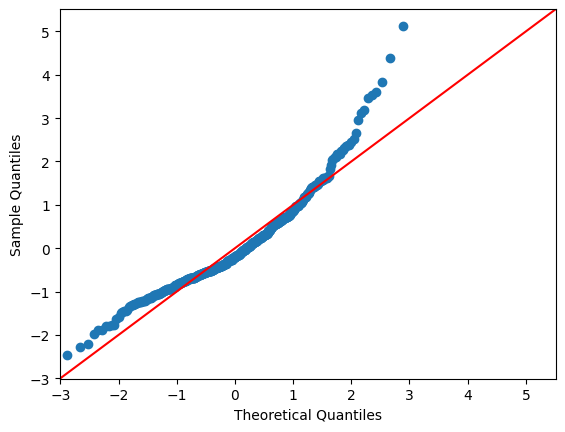

In [25]:
# QQ Plot - Checks if residuals(misses)are normally distributed (bell-shaped)
# res= real price- guess. Positive= guessed to low. Negative= guesses to high
# fit=True, converts model misses from dollars into standard units
# line="45" draws a line where "should be" = "actually is
# Read it: dots on red line= normal. Ends curving away= not normal
# My result: middle is on the line, right end curves up-> skewed right

res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

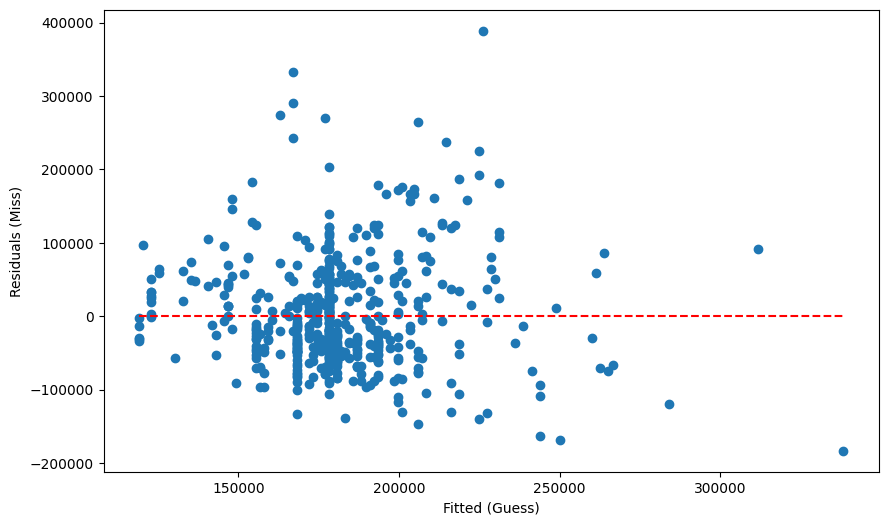

In [26]:
# Residuals vs Fitted (Predicted) Values - Constant variance
#
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted (Guess)")
plt.ylabel("Residuals (Miss)")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;


# Red line at 0 = perfect guess (real price - guess = 0)
# Above the line = guessed too low, house sold for more.
# Below the line = guessed too high. house sold for less
# Distance from the line= size of miss.

#Dot below the line: real price = guess minus the miss
#Dot above the line: real price = guess plus the miss

# Lopsided: biggest misses are above the line -> model badly underguesses expensive houses.
# Same right skew as the QQ plot.

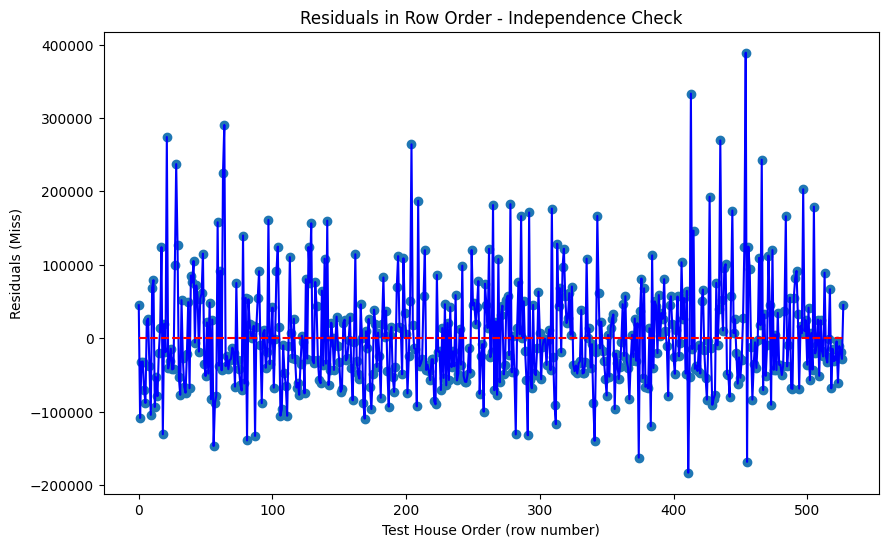

In [27]:
# Residuals vs Time - checks indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Test House Order (row number)")
plt.ylabel("Residuals (Miss)")
plt.title("Residuals in Row Order - Independence Check")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;



# (does one miss tell you anything about the next miss? It shouldn't.)
# Across = house's row number (0, 1, 2...). Up = miss. Blue line connects them in order.
# Good = random zigzag around 0. Bad = waves, trends, or long runs on one side.
# My result: random zigzag, no pattern -> OK.
# Spikes go higher up than down = same right skew as before.
# Caveat: rows were shuffled by train_test_split, so "Time" is just random order.
# This check can't really fail here. Sorting by sale date would make it meaningful.

### Summary of Results
- **Model:** Linear Regression, one feature (Lot Frontage). 80/20 train/test split.
- **Scores:**
  - Test RMSE: \$75,253, how much it missed
  - 100-fold CV RMSE: \$71,856 Close to the test score, so the split wasn't lucky.

- **Compared to guessing the average:**
  - Guessing the average price for every house misses by about $79,225
  - The model is only slightly better, so Lot Frontage alone is a weak predictor.

- **Residual analysis:**
  - QQ plot: the right end curves up → misses are right-skewed.
  - Residuals vs fitted: the biggest misses are expensive houses the model guessed too low.
    - A vertical stripe near $178k = houses filled in with the median (68 ft), which all got the same guess.
    - The 313-ft lot was guessed far too high.

- **Takeaway:** this is the baseline. Every later pass should beat $75k RMSE.
- **Next:** the same feature with Ridge (Pass 05). Expect about the same score.